In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sqlalchemy import text, create_engine, URL

username = "root"
password = "Kuber@123"
server = "localhost"
port = 3306
database = "Car2Insights"

connection_url = URL.create(
    drivername="mysql+pymysql",
    username=username,
    password=password,
    host=server,
    port=port,
    database=database
)

engine = create_engine(connection_url)

with engine.connect() as conn:
    result = conn.execute(text("SELECT DATABASE()"))
    print("Connected Database:", result.scalar())
    

Connected Database: car2insights


In [2]:
overview_query = """
SELECT
    COUNT(DISTINCT order_id) AS total_orders,
    COUNT(DISTINCT customer_id) AS total_customers,
    SUM(total_order_value) AS total_revenue,
    AVG(total_order_value) AS average_order_value,
    AVG(delivery_days) AS average_delivery_days,
    AVG(avg_review_score) AS average_review_score
FROM order_features;
"""

overview_df = pd.read_sql(overview_query, engine)

overview_df

,total_orders,total_customers,total_revenue,average_order_value,average_delivery_days,average_review_score
0,99441,99441,15843553.24,159.326166,12.4973,4.086793


In [3]:
overview_df.T

,0
total_orders,9.944100e+04
total_customers,9.944100e+04
total_revenue,1.584355e+07
average_order_value,1.593262e+02
average_delivery_days,1.249730e+01
average_review_score,4.086793e+00


In [6]:
# ==========================================
# STEP 10.2 - SALES ANALYSIS
# 1. Monthly Sales Trend
# ==========================================

monthly_sales_query = """
SELECT
    DATE_FORMAT(order_purchase_timestamp, '%%Y-%%m') AS sales_month,
    COUNT(DISTINCT order_id) AS total_orders,
    SUM(total_order_value) AS total_revenue,
    AVG(total_order_value) AS average_order_value
FROM order_features
GROUP BY DATE_FORMAT(order_purchase_timestamp, '%%Y-%%m')
ORDER BY sales_month;
"""

monthly_sales_df = pd.read_sql(
    monthly_sales_query,
    engine
)

print("Monthly Sales:")
display(monthly_sales_df)

Monthly Sales:


,sales_month,total_orders,total_revenue,average_order_value
0,2016-09,4,354.75,88.687500
1,2016-10,324,56808.84,175.335926
2,2016-12,1,19.62,19.620000
3,2017-01,800,137188.49,171.485613
4,2017-02,1780,286280.62,160.831809
5,2017-03,2682,432048.59,161.091943
6,2017-04,2404,412422.24,171.556672
7,2017-05,3700,586190.95,158.429986
8,2017-06,3245,502963.04,154.996314
9,2017-07,4026,584971.62,145.298465


In [7]:
# ==========================================
# 2. Revenue by Order Status
# ==========================================

status_sales_query = """
SELECT
    order_status,
    COUNT(DISTINCT order_id) AS total_orders,
    SUM(total_order_value) AS total_revenue,
    AVG(total_order_value) AS average_order_value
FROM order_features
GROUP BY order_status
ORDER BY total_revenue DESC;
"""

status_sales_df = pd.read_sql(
    status_sales_query,
    engine
)

print("Sales by Order Status:")
display(status_sales_df)

Sales by Order Status:


,order_status,total_orders,total_revenue,average_order_value
0,delivered,96478,15419773.75,159.826839
1,shipped,1107,177129.34,160.008437
2,canceled,625,105885.72,169.417152
3,processing,301,69394.11,230.545216
4,invoiced,314,68988.75,219.709395
5,unavailable,609,2140.49,3.514762
6,approved,2,241.08,120.540000
7,created,5,0.00,0.000000


In [8]:
# ==========================================
# 3. Top 10 Product Categories by Revenue
# ==========================================

category_sales_query = """
SELECT
    product_category_name,
    order_count,
    item_count,
    category_revenue,
    avg_item_value
FROM category_features
ORDER BY category_revenue DESC
LIMIT 10;
"""

top_categories_df = pd.read_sql(
    category_sales_query,
    engine
)

print("Top 10 Product Categories by Revenue:")
display(top_categories_df)

Top 10 Product Categories by Revenue:


,product_category_name,order_count,item_count,category_revenue,avg_item_value
0,beleza_saude,8836,9670,1441248.07,149.043234
1,relogios_presentes,5624,5991,1305541.61,217.917144
2,cama_mesa_banho,9417,11115,1241681.72,111.712256
3,esporte_lazer,7720,8641,1156656.48,133.856785
4,informatica_acessorios,6689,7827,1059272.40,135.335684
5,moveis_decoracao,6449,8334,902511.79,108.292751
6,utilidades_domesticas,5884,6964,778397.77,111.774522
7,cool_stuff,3632,3796,719329.95,189.496826
8,automotivo,3897,4235,685384.32,161.838092
9,ferramentas_jardim,3518,4347,584219.21,134.395954


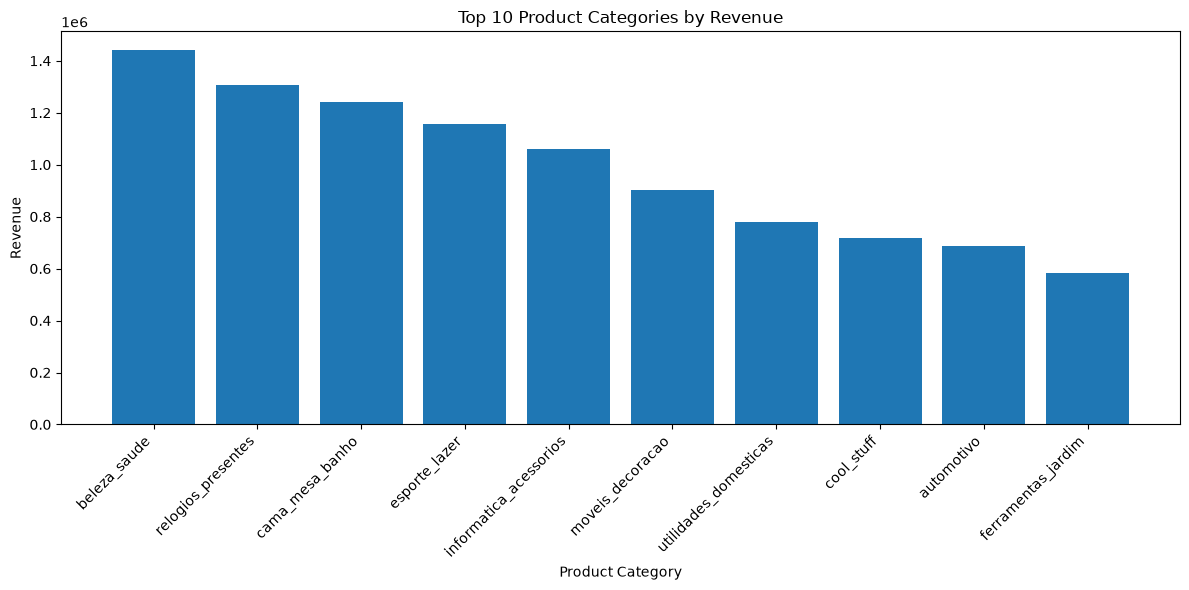

In [9]:
# ==========================================
# 4. Top 10 Categories - Revenue Chart
# ==========================================

plt.figure(figsize=(12, 6))

plt.bar(
    top_categories_df["product_category_name"],
    top_categories_df["category_revenue"]
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

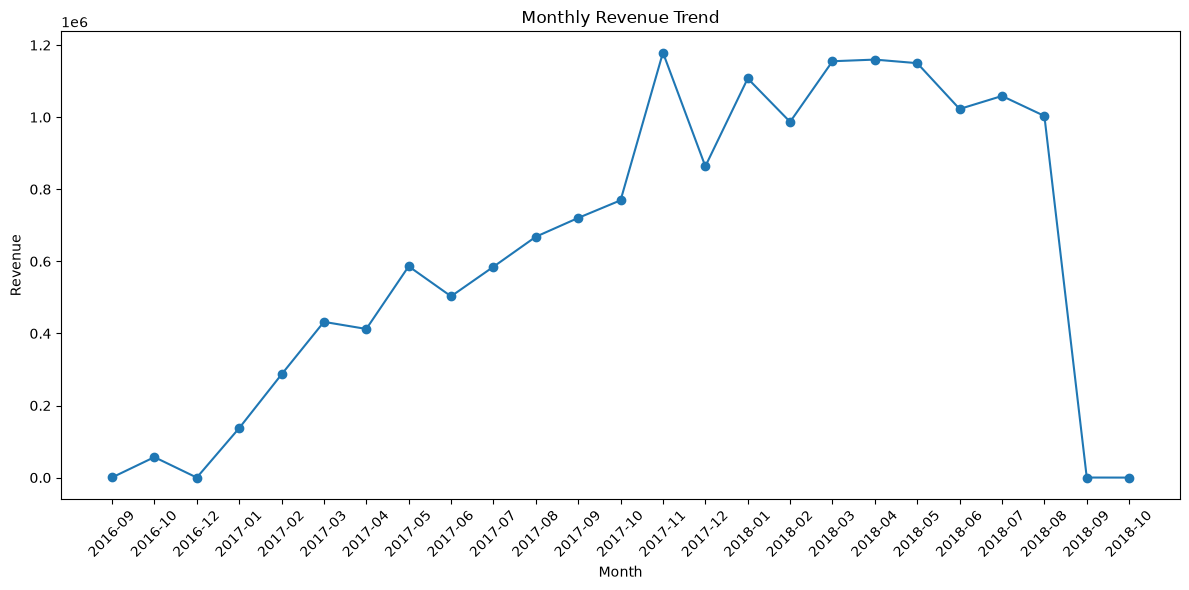

In [10]:
# ==========================================
# 5. Monthly Revenue Trend
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales_df["sales_month"],
    monthly_sales_df["total_revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

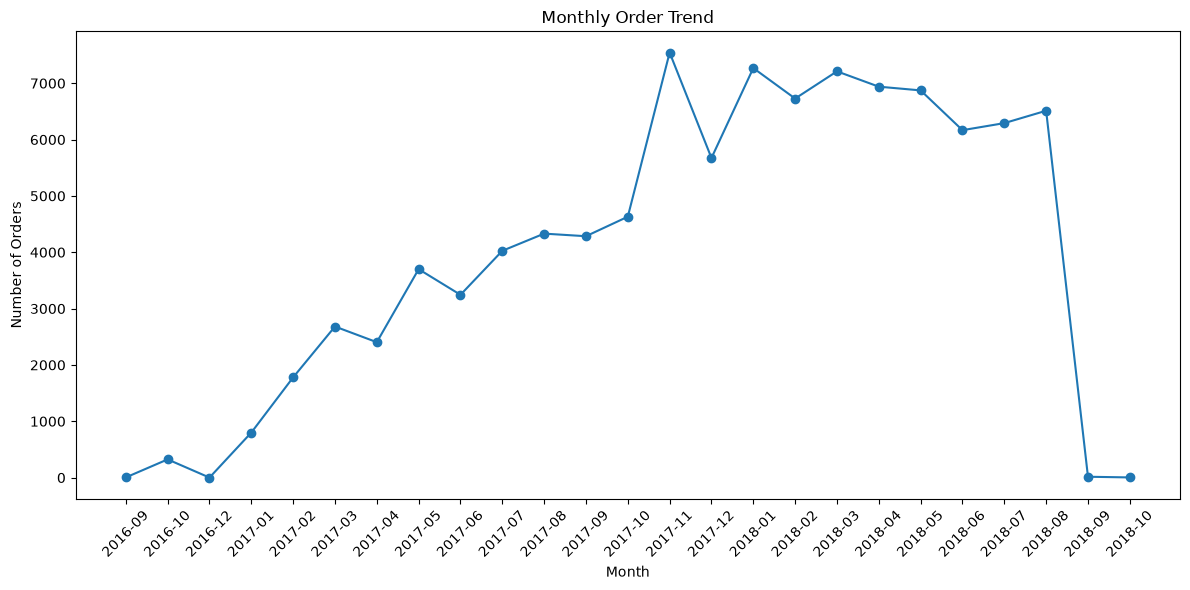

In [11]:
# ==========================================
# 6. Monthly Order Count
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales_df["sales_month"],
    monthly_sales_df["total_orders"],
    marker="o"
)

plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [12]:
# ==========================================
# STEP 10.3 - CUSTOMER ANALYSIS
# 1. Customer Overview
# ==========================================

customer_overview_query = """
SELECT
    COUNT(DISTINCT customer_id) AS total_customers,
    SUM(CASE WHEN repeat_customer = 0 THEN 1 ELSE 0 END) AS new_customers,
    SUM(CASE WHEN repeat_customer = 1 THEN 1 ELSE 0 END) AS repeat_customers,
    AVG(customer_total_spending) AS average_customer_spending,
    MAX(customer_total_spending) AS highest_customer_spending
FROM customer_features;
"""

customer_overview_df = pd.read_sql(
    customer_overview_query,
    engine
)

display(customer_overview_df)

,total_customers,new_customers,repeat_customers,average_customer_spending,highest_customer_spending
0,99441,99441.0,0.0,159.326166,13664.08


In [13]:
# ==========================================
# 2. New vs Repeat Customers
# ==========================================

customer_type_query = """
SELECT
    CASE
        WHEN repeat_customer = 1 THEN 'Repeat Customer'
        ELSE 'New Customer'
    END AS customer_type,
    COUNT(*) AS customer_count,
    ROUND(
        COUNT(*) * 100.0 /
        (SELECT COUNT(*) FROM customer_features),
        2
    ) AS percentage
FROM customer_features
GROUP BY repeat_customer
ORDER BY customer_count DESC;
"""

customer_type_df = pd.read_sql(
    customer_type_query,
    engine
)

display(customer_type_df)

,customer_type,customer_count,percentage
0,New Customer,99441,100.0


In [14]:
# ==========================================
# 3. Top 10 Customers by Spending
# ==========================================

top_customers_query = """
SELECT
    customer_id,
    customer_order_count,
    customer_total_spending,
    average_order_value,
    repeat_customer
FROM customer_features
ORDER BY customer_total_spending DESC
LIMIT 10;
"""

top_customers_df = pd.read_sql(
    top_customers_query,
    engine
)

display(top_customers_df)

,customer_id,customer_order_count,customer_total_spending,average_order_value,repeat_customer
0,1617b1357756262bfa56ab541c47bc16,1,13664.08,13664.08,0
1,ec5b2ba62e574342386871631fafd3fc,1,7274.88,7274.88,0
2,c6e2731c5b391845f6800c97401a43a9,1,6929.31,6929.31,0
3,f48d464a0baaea338cb25f816991ab1f,1,6922.21,6922.21,0
4,3fd6777bbce08a352fddd04e4a7cc8f6,1,6726.66,6726.66,0
5,05455dfa7cd02f13d132aa7a6a9729c6,1,6081.54,6081.54,0
6,df55c14d1476a9a3467f131269c2477f,1,4950.34,4950.34,0
7,e0a2412720e9ea4f26c1ac985f6a7358,1,4809.44,4809.44,0
8,24bbf5fd2f2e1b359ee7de94defc4a15,1,4764.34,4764.34,0
9,3d979689f636322c62418b6346b1c6d2,1,4681.78,4681.78,0


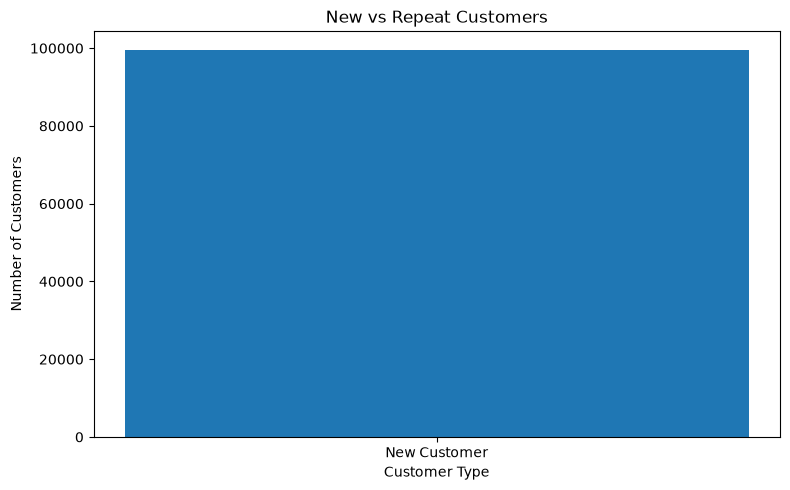

In [15]:
# ==========================================
# 4. New vs Repeat Customer Chart
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    customer_type_df["customer_type"],
    customer_type_df["customer_count"]
)

plt.title("New vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

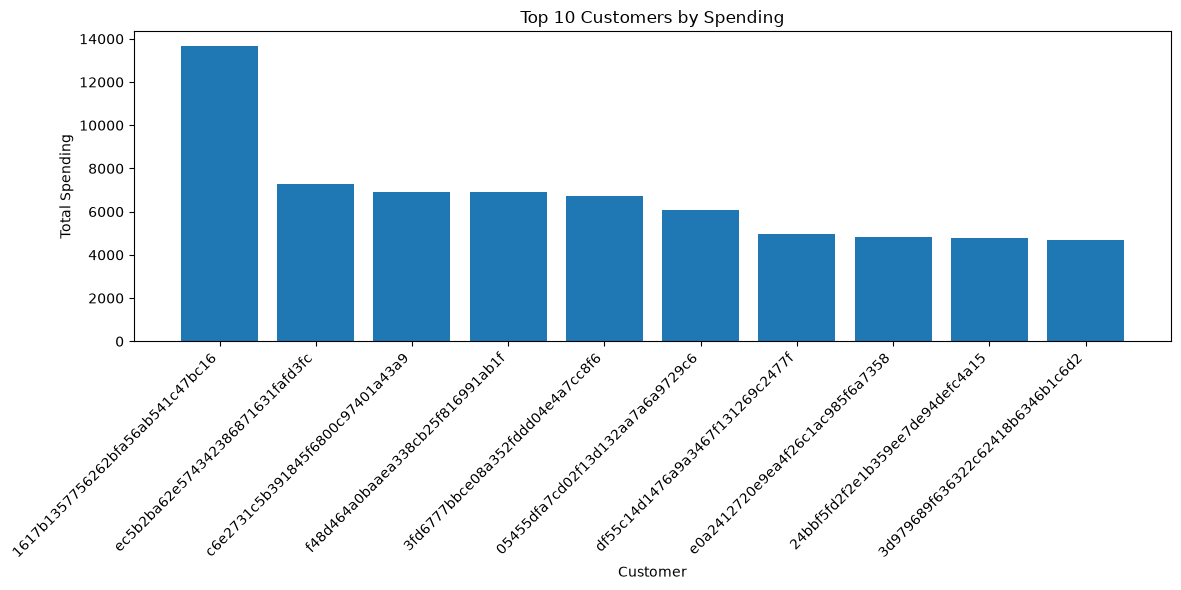

In [16]:
# ==========================================
# 5. Top 10 Customers by Spending
# ==========================================

plt.figure(figsize=(12, 6))

plt.bar(
    top_customers_df["customer_id"].astype(str),
    top_customers_df["customer_total_spending"]
)

plt.title("Top 10 Customers by Spending")
plt.xlabel("Customer")
plt.ylabel("Total Spending")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [17]:
# ==========================================
# STEP 10.4 - SELLER & PRODUCT ANALYSIS
# 1. Top 10 Sellers by Revenue
# ==========================================

seller_revenue_query = """
SELECT
    seller_id,
    seller_order_count,
    seller_revenue,
    average_item_value
FROM seller_features
ORDER BY seller_revenue DESC
LIMIT 10;
"""

top_sellers_revenue_df = pd.read_sql(
    seller_revenue_query,
    engine
)

display(top_sellers_revenue_df)


,seller_id,seller_order_count,seller_revenue,average_item_value
0,4869f7a5dfa277a7dca6462dcf3b52b2,1132,249640.70,215.952163
1,7c67e1448b00f6e969d365cea6b010ab,982,239536.44,175.613226
2,53243585a1d6dc2643021fd1853d8905,358,235856.68,575.260195
3,4a3ca9315b744ce9f8e9374361493884,1806,235539.96,118.540493
4,fa1c13f2614d7b5c4749cbc52fecda94,585,204084.73,348.267457
5,da8622b14eb17ae2831f4ac5b9dab84a,1314,185192.32,119.401883
6,7e93a43ef30c4f03f38b393420bc753a,336,182754.05,537.511912
7,1025f0e2d44d7041d6cf58b6550e0bfa,915,172860.69,121.050903
8,7a67c85e85bb2ce8582c35f2203ad736,1160,162648.38,138.896994
9,955fee9216a65b617aa5c0531780ce60,1287,160602.68,107.139880


In [18]:
# ==========================================
# 2. Top 10 Sellers by Order Count
# ==========================================

seller_orders_query = """
SELECT
    seller_id,
    seller_order_count,
    seller_revenue,
    average_item_value
FROM seller_features
ORDER BY seller_order_count DESC
LIMIT 10;
"""

top_sellers_orders_df = pd.read_sql(
    seller_orders_query,
    engine
)

display(top_sellers_orders_df)

,seller_id,seller_order_count,seller_revenue,average_item_value
0,6560211a19b47992c3666cc44a7e94c0,1854,151265.77,74.405199
1,4a3ca9315b744ce9f8e9374361493884,1806,235539.96,118.540493
2,cc419e0650a3c5ba77189a1882b7556a,1706,129957.41,73.215442
3,1f50f920176fa81dab994f9023523100,1404,142104.98,73.591393
4,da8622b14eb17ae2831f4ac5b9dab84a,1314,185192.32,119.401883
5,955fee9216a65b617aa5c0531780ce60,1287,160602.68,107.139880
6,7a67c85e85bb2ce8582c35f2203ad736,1160,162648.38,138.896994
7,ea8482cd71df3c1969d7b9473ff13abc,1146,54722.29,45.488188
8,4869f7a5dfa277a7dca6462dcf3b52b2,1132,249640.70,215.952163
9,3d871de0142ce09b7081e2b9d1733cb1,1080,117347.71,102.308378


In [19]:
# ==========================================
# 3. Top 10 Product Categories
# ==========================================

product_category_query = """
SELECT
    product_category_name,
    order_count,
    item_count,
    category_revenue,
    avg_item_value
FROM category_features
ORDER BY category_revenue DESC
LIMIT 10;
"""

top_product_categories_df = pd.read_sql(
    product_category_query,
    engine
)

display(top_product_categories_df)

,product_category_name,order_count,item_count,category_revenue,avg_item_value
0,beleza_saude,8836,9670,1441248.07,149.043234
1,relogios_presentes,5624,5991,1305541.61,217.917144
2,cama_mesa_banho,9417,11115,1241681.72,111.712256
3,esporte_lazer,7720,8641,1156656.48,133.856785
4,informatica_acessorios,6689,7827,1059272.40,135.335684
5,moveis_decoracao,6449,8334,902511.79,108.292751
6,utilidades_domesticas,5884,6964,778397.77,111.774522
7,cool_stuff,3632,3796,719329.95,189.496826
8,automotivo,3897,4235,685384.32,161.838092
9,ferramentas_jardim,3518,4347,584219.21,134.395954


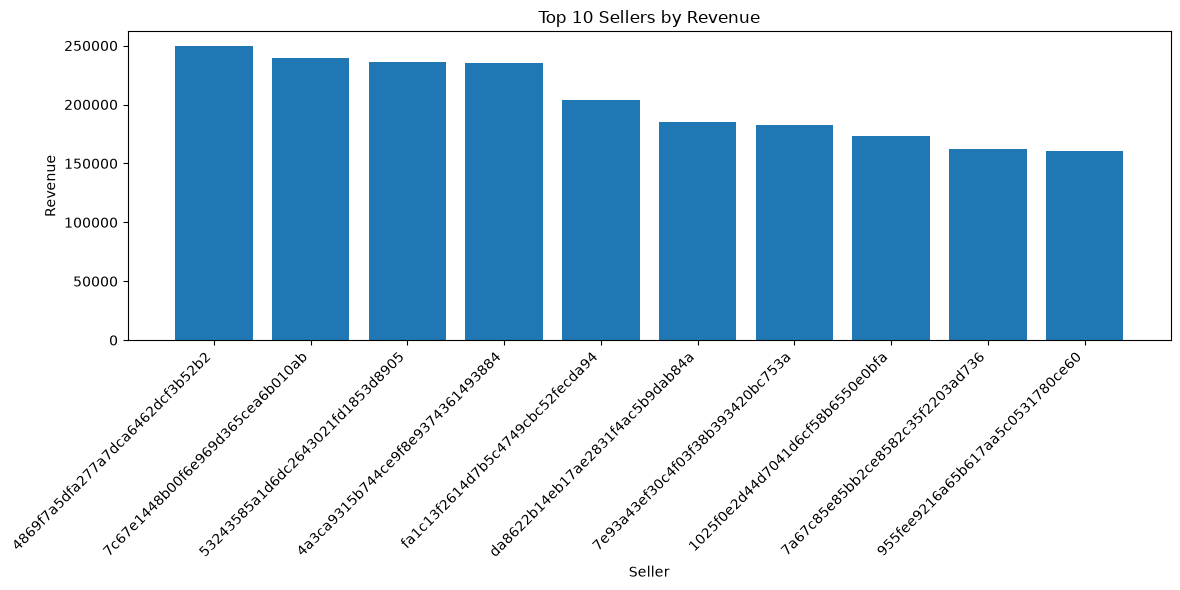

In [20]:
    # ==========================================
# 4. Top Sellers by Revenue
# ==========================================

plt.figure(figsize=(12, 6))

plt.bar(
    top_sellers_revenue_df["seller_id"].astype(str),
    top_sellers_revenue_df["seller_revenue"]
)

plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Seller")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

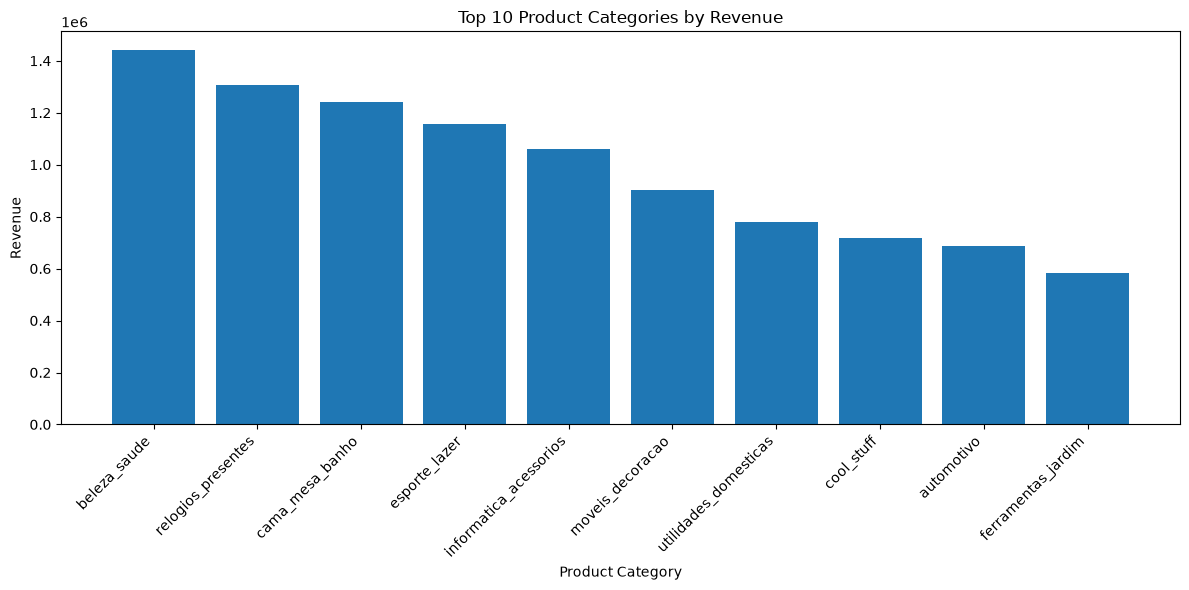

In [21]:
# ==========================================
# 5. Top Product Categories by Revenue
# ==========================================

plt.figure(figsize=(12, 6))

plt.bar(
    top_product_categories_df["product_category_name"],
    top_product_categories_df["category_revenue"]
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [22]:
# ==========================================
# STEP 10.5 - DELIVERY ANALYSIS
# 1. Delivery Overview
# ==========================================

delivery_overview_query = """
SELECT
    COUNT(DISTINCT order_id) AS total_orders,
    SUM(CASE WHEN delivery_status = 'On Time' THEN 1 ELSE 0 END) AS on_time_orders,
    SUM(CASE WHEN delivery_status = 'Delayed' THEN 1 ELSE 0 END) AS delayed_orders,
    AVG(delivery_days) AS average_delivery_days,
    AVG(delivery_delay_days) AS average_delay_days
FROM order_features
WHERE delivery_status IN ('On Time', 'Delayed');
"""

delivery_overview_df = pd.read_sql(
    delivery_overview_query,
    engine
)

display(delivery_overview_df)

,total_orders,on_time_orders,delayed_orders,average_delivery_days,average_delay_days
0,96476,88649.0,7827.0,12.4973,0.7194


In [23]:
# ==========================================
# 2. Delivery Status Distribution
# ==========================================

delivery_status_query = """
SELECT
    delivery_status,
    COUNT(DISTINCT order_id) AS order_count,
    ROUND(
        COUNT(DISTINCT order_id) * 100.0 /
        (
            SELECT COUNT(DISTINCT order_id)
            FROM order_features
            WHERE delivery_status IN ('On Time', 'Delayed')
        ),
        2
    ) AS percentage
FROM order_features
WHERE delivery_status IN ('On Time', 'Delayed')
GROUP BY delivery_status
ORDER BY order_count DESC;
"""

delivery_status_df = pd.read_sql(
    delivery_status_query,
    engine
)

display(delivery_status_df)

,delivery_status,order_count,percentage
0,On Time,88649,91.89
1,Delayed,7827,8.11


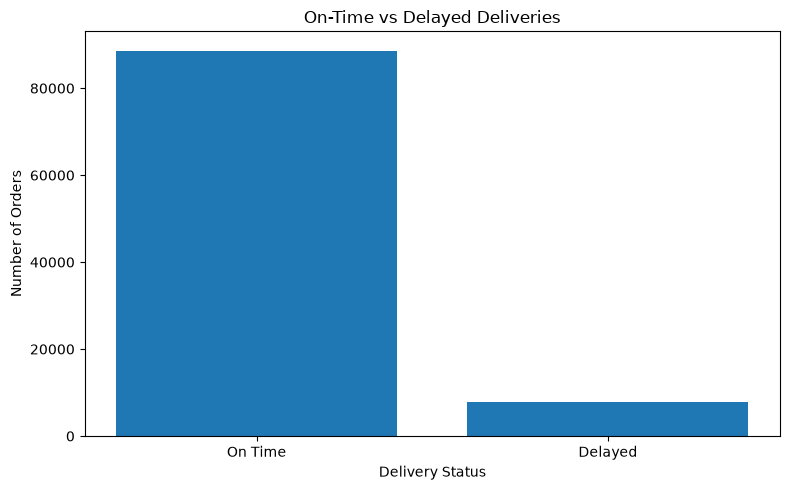

In [24]:
# ==========================================
# 3. Delivery Status Chart
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    delivery_status_df["delivery_status"],
    delivery_status_df["order_count"]
)

plt.title("On-Time vs Delayed Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

In [25]:
# ==========================================
# 4. Monthly Delivery Performance
# ==========================================

monthly_delivery_query = """
SELECT
    DATE_FORMAT(order_purchase_timestamp, '%%Y-%%m') AS delivery_month,

    COUNT(DISTINCT order_id) AS total_orders,

    SUM(
        CASE
            WHEN delivery_status = 'On Time' THEN 1
            ELSE 0
        END
    ) AS on_time_orders,

    SUM(
        CASE
            WHEN delivery_status = 'Delayed' THEN 1
            ELSE 0
        END
    ) AS delayed_orders,

    AVG(delivery_days) AS average_delivery_days,

    AVG(delivery_delay_days) AS average_delay_days

FROM order_features

WHERE delivery_status IN ('On Time', 'Delayed')

GROUP BY DATE_FORMAT(order_purchase_timestamp, '%%Y-%%m')

ORDER BY delivery_month;
"""

monthly_delivery_df = pd.read_sql(
    monthly_delivery_query,
    engine
)

display(monthly_delivery_df)

,delivery_month,total_orders,on_time_orders,delayed_orders,average_delivery_days,average_delay_days
0,2016-09,1,0.0,1.0,55.0000,36.0000
1,2016-10,270,267.0,3.0,19.6111,0.0704
2,2016-12,1,1.0,0.0,5.0000,0.0000
3,2017-01,750,727.0,23.0,12.7533,0.5933
4,2017-02,1653,1600.0,53.0,13.3001,0.6165
5,2017-03,2546,2404.0,142.0,13.0444,1.1587
6,2017-04,2303,2122.0,181.0,15.0230,0.8089
7,2017-05,3545,3417.0,128.0,11.4271,0.3749
8,2017-06,3135,3014.0,121.0,12.0128,0.4322
9,2017-07,3872,3739.0,133.0,11.4889,0.3259


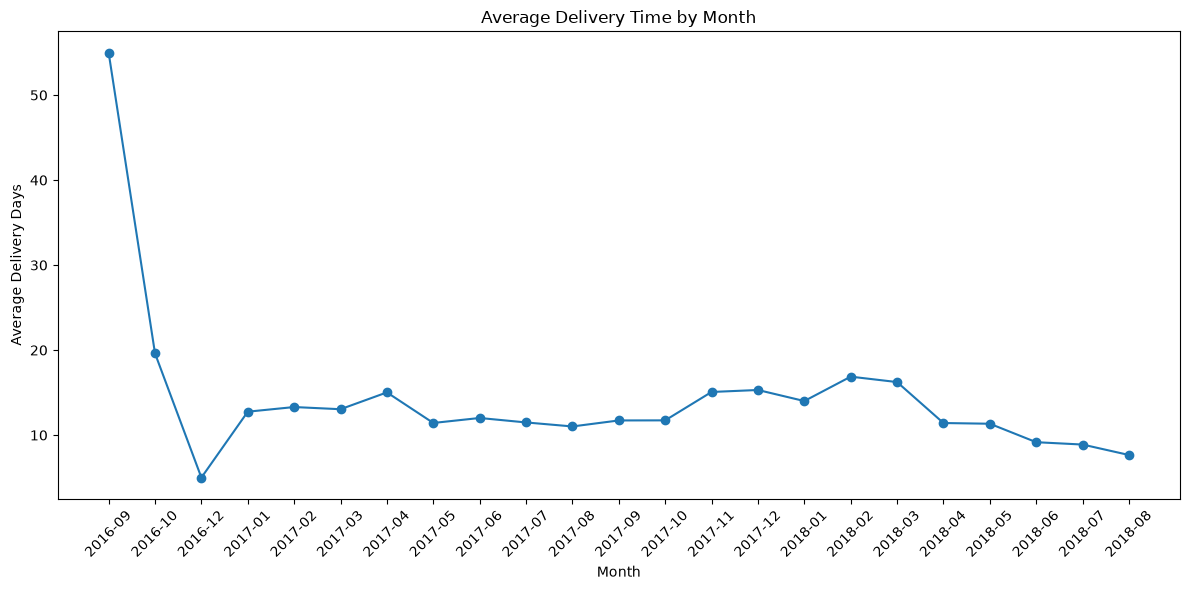

In [26]:
# ==========================================
# 5. Average Delivery Time by Month
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_delivery_df["delivery_month"],
    monthly_delivery_df["average_delivery_days"],
    marker="o"
)

plt.title("Average Delivery Time by Month")
plt.xlabel("Month")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
# ==========================================
# STEP 10.6 - CUSTOMER EXPERIENCE
# 1. Review Score Overview
# ==========================================

review_overview_query = """
SELECT
    COUNT(*) AS total_orders_with_review,
    AVG(avg_review_score) AS average_review_score,
    MIN(avg_review_score) AS minimum_review_score,
    MAX(avg_review_score) AS maximum_review_score
FROM order_features
WHERE avg_review_score IS NOT NULL;
"""

review_overview_df = pd.read_sql(
    review_overview_query,
    engine
)

display(review_overview_df)

,total_orders_with_review,average_review_score,minimum_review_score,maximum_review_score
0,98673,4.086793,1.0,5.0


In [28]:
# ==========================================
# 2. Review Score Distribution
# ==========================================

review_distribution_query = """
SELECT
    ROUND(avg_review_score) AS review_score,
    COUNT(*) AS order_count
FROM order_features
WHERE avg_review_score IS NOT NULL
GROUP BY ROUND(avg_review_score)
ORDER BY review_score;
"""

review_distribution_df = pd.read_sql(
    review_distribution_query,
    engine
)

display(review_distribution_df)

,review_score,order_count
0,1.0,11316
1,2.0,3133
2,3.0,8171
3,4.0,19044
4,5.0,57009


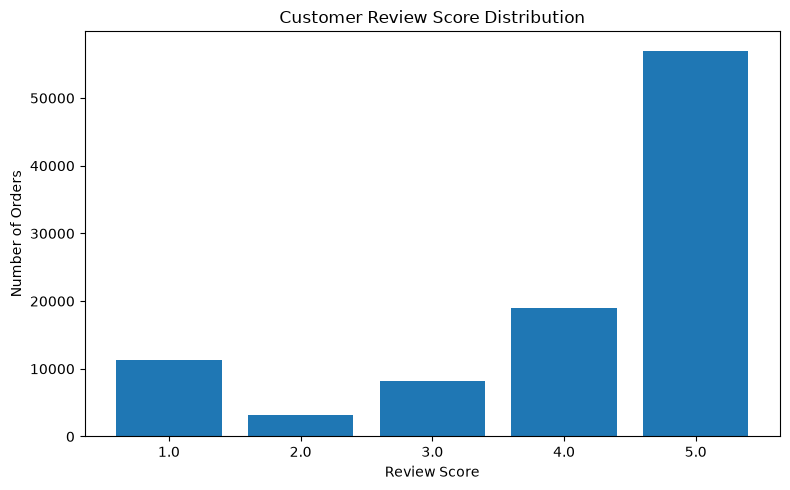

In [29]:
# ==========================================
# 3. Review Score Chart
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    review_distribution_df["review_score"].astype(str),
    review_distribution_df["order_count"]
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

In [30]:
# ==========================================
# 4. Review Score by Delivery Status
# ==========================================

delivery_review_query = """
SELECT
    delivery_status,
    COUNT(*) AS order_count,
    AVG(avg_review_score) AS average_review_score
FROM order_features
WHERE
    avg_review_score IS NOT NULL
    AND delivery_status IN ('On Time', 'Delayed')
GROUP BY delivery_status
ORDER BY average_review_score DESC;
"""

delivery_review_df = pd.read_sql(
    delivery_review_query,
    engine
)

display(delivery_review_df)

,delivery_status,order_count,average_review_score
0,On Time,88168,4.294151
1,Delayed,7662,2.566562


In [31]:
# ==========================================
# 4. Review Score by Delivery Status
# ==========================================

delivery_review_query = """
SELECT
    delivery_status,
    COUNT(*) AS order_count,
    AVG(avg_review_score) AS average_review_score
FROM order_features
WHERE
    avg_review_score IS NOT NULL
    AND delivery_status IN ('On Time', 'Delayed')
GROUP BY delivery_status
ORDER BY average_review_score DESC;
"""

delivery_review_df = pd.read_sql(
    delivery_review_query,
    engine
)

display(delivery_review_df)

,delivery_status,order_count,average_review_score
0,On Time,88168,4.294151
1,Delayed,7662,2.566562


In [32]:
# ==========================================
# 5. Payment Method Analysis
# ==========================================

payment_experience_query = """
SELECT
    payment_type,
    COUNT(DISTINCT order_id) AS order_count,
    SUM(total_order_value) AS total_revenue,
    AVG(total_order_value) AS average_order_value,
    AVG(avg_review_score) AS average_review_score
FROM order_features
WHERE payment_type IS NOT NULL
GROUP BY payment_type
ORDER BY total_revenue DESC;
"""

payment_experience_df = pd.read_sql(
    payment_experience_query,
    engine
)

display(payment_experience_df)

,payment_type,order_count,total_revenue,average_order_value,average_review_score
0,credit_card,76504,12623817.56,165.008595,4.088148
1,boleto,19784,2842240.29,143.663581,4.087136
2,debit_card,1528,215260.54,140.877317,4.169954
3,voucher,1621,162091.39,99.994688,3.945901
4,not_defined,3,0.00,0.000000,1.666667


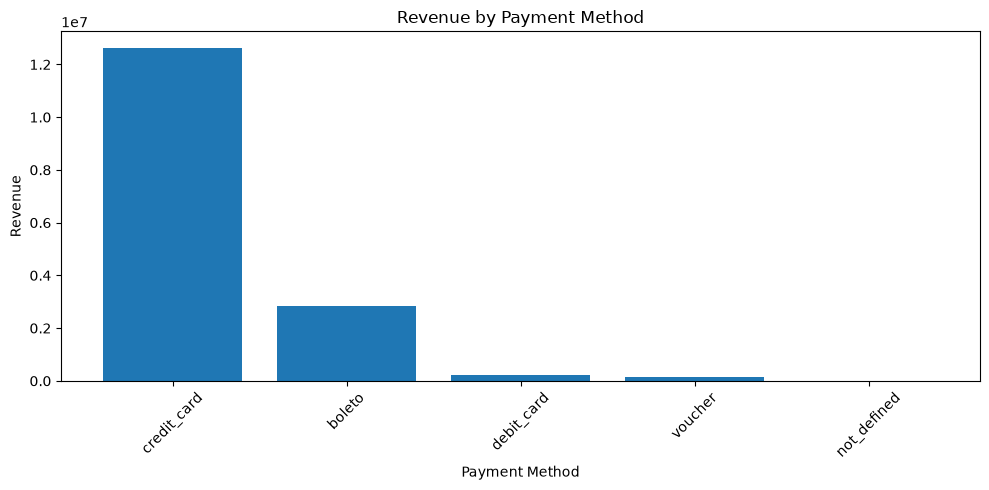

In [33]:
# ==========================================
# 6. Payment Method by Revenue
# ==========================================

plt.figure(figsize=(10, 5))

plt.bar(
    payment_experience_df["payment_type"],
    payment_experience_df["total_revenue"]
)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()